# 📊 Cuaderno 1: Auditoría de Calidad y Perfilado de Datos
## Proyecto de Ciencia de Datos (X Semestre) - Segundo Corte
### Caso de Estudio: Inside Airbnb (New York City)

---

### 🎯 Objetivos de este Cuaderno:
1. **Perfilado Inicial:** Comprender la estructura, volumetría y tipologías del dataset crudo (`listings.csv.gz`).
2. **Aplicación de Técnicas de Clase:**
   - Detección de registros completamente vacíos (`dropna(how='all')`).
   - Detección y evaluación de filas incompletas por umbral de variables válidas.
   - Auditoría de duplicados exactos y por clave primaria (`id`).
3. **Diagnóstico de Patrones de Nulos:** Clasificar columnas con valores ausentes y entender su naturaleza de negocio.
4. **Detección de Datos Corruptos y No Tabulares:** Identificar strings de moneda, variables booleanas en texto y listas JSON anidadas.
5. **Auditoría de Outliers y Regulación:** Evaluar valores atípicos en tarifas y estancias mínimas frente a la **Local Law 18** de NYC.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("../..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_listings
from src.cleaning import audit_dataset

# Configuración visual
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

print("✅ Entorno y dependencias cargadas correctamente.")

✅ Entorno y dependencias cargadas correctamente.


---
## 1. Carga del Dataset Crudo
Cargamos el archivo oficial `listings.csv.gz` de New York City.

In [2]:
df_raw = load_raw_listings("nyc")
print(f"Dimensiones crudas: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas.")
df_raw.head(3)

📖 Cargando /Users/jyarar/projects/u/x-semestre/data-science/data/selected/airbnb/raw/nyc/listings.csv.gz...


📊 Dataset cargado: 30,259 filas x 90 columnas.
Dimensiones crudas: 30,259 filas x 90 columnas.


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2539,https://www.airbnb.com/rooms/2539,20260614073253,2026-06-15,city scrape,11 Min to Manhattan • Prospect Park • Fast WiFi,"Bright, serene room in a renovated apartment h...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,2787,...,5.0,4.78,4.78,NaN,NaN,5,0,5,0,0.08
1,6848,https://www.airbnb.com/rooms/6848,20260614073253,2026-06-14,city scrape,Only 2 stops to Manhattan studio,Comfortable studio apartment with super comfor...,NaN,https://a0.muscache.com/pictures/e4f031a7-f146...,15991,...,4.8,4.69,4.59,NaN,NaN,1,1,0,0,0.95
2,6872,https://www.airbnb.com/rooms/6872,20260614073253,2026-06-14,city scrape,Uptown Sanctuary w/ Private Bath (Month to Month),This charming distancing-friendly month-to-mon...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,16104,...,5.0,5.00,5.00,NaN,NaN,2,0,2,0,0.04


---
## 2. Aplicación de las Técnicas de Diagnóstico Vistas en Clase

Replicamos y formalizamos los diagnósticos vistos en las bitácoras de clase:
1. **Vacíos totales:** Filas donde todas las columnas sean NaN.
2. **Filas incompletas:** Filas con un número muy bajo de atributos válidos.
3. **Duplicados:** Detección de duplicación de filas completas y claves primarias (`id`).

In [3]:
audit_results = audit_dataset(df_raw, incomplete_threshold=15)

print("=" * 60)
print("📋 RESUMEN DE AUDITORÍA DE CALIDAD DE DATOS (TÉCNICAS DE CLASE)")
print("=" * 60)
print(f"Total de Filas:                     {audit_results['total_rows']:,}")
print(f"Total de Columnas:                  {audit_results['total_cols']:,}")
print(f"Filas 100% Vacías:                  {audit_results['empty_rows']:,}")
print(f"Filas Incompletas (<= 15 cols):     {audit_results['incomplete_rows']:,}")
print(f"Duplicados Totales:                 {audit_results['total_duplicates']:,}")
print(f"Duplicados por ID de Alojamiento:   {audit_results['id_duplicates']:,}")
print("=" * 60)

📋 RESUMEN DE AUDITORÍA DE CALIDAD DE DATOS (TÉCNICAS DE CLASE)
Total de Filas:                     30,259
Total de Columnas:                  90
Filas 100% Vacías:                  0
Filas Incompletas (<= 15 cols):     0
Duplicados Totales:                 0
Duplicados por ID de Alojamiento:   0


---
## 3. Diagnóstico Exhaustivo de Valores Ausentes (*Missing Values*)

Analizamos la distribución de nulos para identificar variables irrecuperables vs variables que requieren imputación semántica.

Top 15 variables con mayor porcentaje de nulos:


,columna,tipo,nulos_conteo,nulos_porcentaje
0,neighbourhood,float64,30259,100.00
1,host_since,float64,30259,100.00
2,host_neighbourhood,float64,30259,100.00
3,host_thumbnail_url,float64,30259,100.00
4,host_acceptance_rate,float64,30259,100.00
5,host_response_rate,float64,30259,100.00
6,host_response_time,float64,30259,100.00
7,host_verifications,float64,30259,100.00
8,host_total_listings_count,float64,30259,100.00
9,neighborhood_overview,float64,30259,100.00


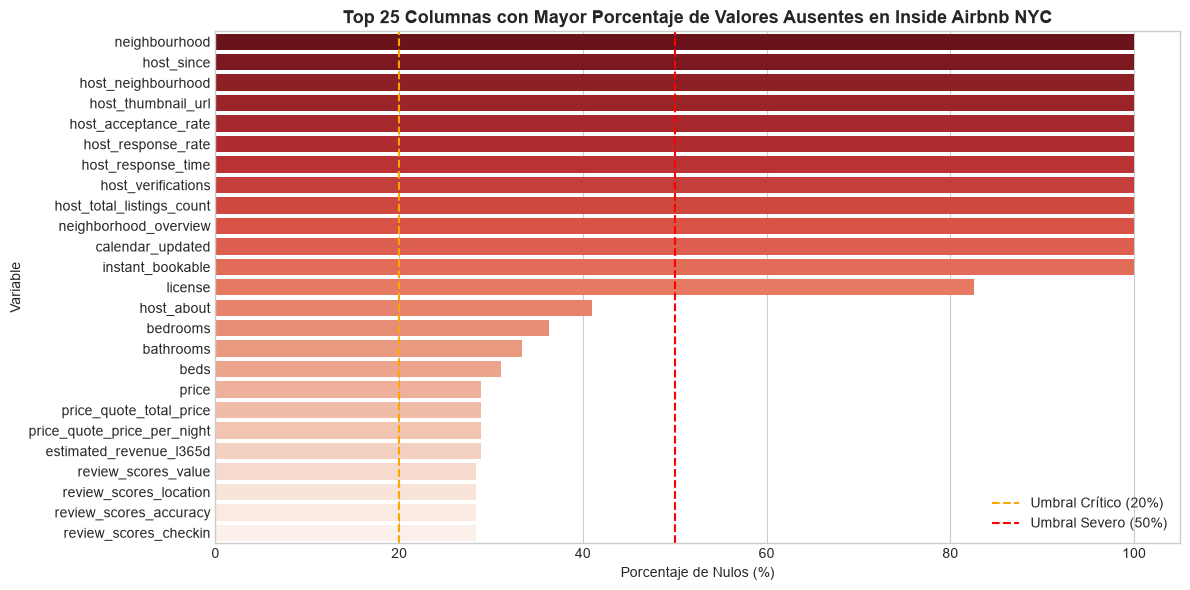

In [4]:
missing_df = audit_results["missing_summary"]
top_missing = missing_df[missing_df["nulos_porcentaje"] > 0].head(25)

print("Top 15 variables con mayor porcentaje de nulos:")
display(top_missing.head(15))

# Gráfico de barras de valores ausentes
plt.figure(figsize=(12, 6))
sns.barplot(data=top_missing, x="nulos_porcentaje", y="columna", palette="Reds_r", hue="columna", legend=False)
plt.title("Top 25 Columnas con Mayor Porcentaje de Valores Ausentes en Inside Airbnb NYC", fontsize=13, fontweight="bold")
plt.xlabel("Porcentaje de Nulos (%)")
plt.ylabel("Variable")
plt.axvline(x=20, color="orange", linestyle="--", label="Umbral Crítico (20%)")
plt.axvline(x=50, color="red", linestyle="--", label="Umbral Severo (50%)")
plt.legend()
plt.tight_layout()
plt.show()

---
## 4. Auditoría de Variables Específicas del Problema

Revisamos la naturaleza de las variables clave para el modelado predictivo:
- `price`: Formato moneda textual con signos de dólar y comas (`"$120.00"`).
- `bathrooms_text`: Cadenas descriptivas de baños.
- `amenities`: Listas en formato JSON textual anidado.
- `minimum_nights`: Outliers y contexto regulatorio de NYC (**Local Law 18**).

In [5]:
# 1. Inspección del campo price
print("Muestra de valores crudos en 'price':")
print(df_raw["price"].dropna().head(10).tolist())
print(f"Total de nulos en price: {df_raw['price'].isna().sum():,} ({df_raw['price'].isna().mean()*100:.2f}%)")

# 2. Inspección de bathrooms_text
print("\nMuestra de valores crudos en 'bathrooms_text':")
print(df_raw["bathrooms_text"].dropna().value_counts().head(8))

# 3. Inspección de amenities
print("\nMuestra de valores crudos en 'amenities' (registro 0):")
print(str(df_raw["amenities"].iloc[0])[:200] + "...")

# 4. Inspección de minimum_nights y regulación Local Law 18
print("\nDistribución de estancia mínima (Local Law 18):")
corta_estancia = (df_raw["minimum_nights"] < 30).sum()
larga_estancia = (df_raw["minimum_nights"] >= 30).sum()
print(f"Corta estancia (< 30 días):  {corta_estancia:,} ({corta_estancia / len(df_raw)*100:.1f}%)")
print(f"Media/larga estancia (>= 30): {larga_estancia:,} ({larga_estancia / len(df_raw)*100:.1f}%)")
print(f"Outliers extremos (> 365):    {(df_raw['minimum_nights'] > 365).sum():,}")

Muestra de valores crudos en 'price':
['$113.97', '$117.27', '$80.06', '$77.17', '$202.47', '$365.97', '$154.87', '$91.07', '$159.77', '$87.77']
Total de nulos en price: 8,744 (28.90%)

Muestra de valores crudos en 'bathrooms_text':
bathrooms_text
1 bath              14783
1 shared bath        5733
1 private bath       3945
2 baths              2319
1.5 baths             825
2 shared baths        817
1.5 shared baths      466
2.5 baths             312
Name: count, dtype: int64

Muestra de valores crudos en 'amenities' (registro 0):
["Bed linens", "Hot water", "Exterior security cameras on property", "Cleaning products", "Fire extinguisher", "Elevator", "Lockbox", "Microwave", "Laundromat nearby", "Oven", "Portable fans", "Self c...

Distribución de estancia mínima (Local Law 18):
Corta estancia (< 30 días):  5,540 (18.3%)
Media/larga estancia (>= 30): 24,717 (81.7%)
Outliers extremos (> 365):    17


---
## 5. Conclusiones y Diagnóstico para la Fase de Limpieza

| Aspecto Evaluado | Hallazgo en Inside Airbnb NYC | Acción Requerida en Limpieza |
| :--- | :--- | :--- |
| **Integridad de Registros** | 0 filas completamente vacías y 0 duplicados exactos. | El scraping preservó integridad de identificadores. |
| **Variable Objetivo (`price`)** | 28.9% de nulos; formato string con `$` y comas; valores extremos (\$0 o > \$2,000). | Parsear a `float`, descartar nulos y filtrar outliers justificados (\$10 a \$2,000). |
| **Infraestructura (`bedrooms`, `beds`)** | ~31% a 36% de nulos. | Imputar semánticamente a partir de `accommodates` (capacidad máxima). |
| **Comodidades (`amenities`)** | Strings anidados en listas JSON. | Desanidar y binarizar indicadores clave (Wifi, AC, Cocina, etc.). |
| **Regulación NYC** | 82%+ de los listados tienen estancias mínimas ≥ 30 días por la ley Local Law 18. | Conservar indicador de tipo de estancia y remover errores de digitación (> 365 días). |